## Flow will be

START -> user topic -> I/P guardrail -> LLM <-> mcp tools 

LLM -> o/p guardrail -> Final Response -> END

In [1]:
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph import START, END, StateGraph
import os
from dotenv import load_dotenv

In [2]:
load_dotenv()  # Load environment variables from .env file

True

In [3]:
from langgraph.graph.message import add_messages

class State(TypedDict):
    topic: str
    messages: Annotated[list, add_messages]  # we need this to call ToolNode for calling MCP tools like tavily search

In [ ]:
import feedparser
import arxiv
from langchain_core.tools import tool


import feedparser
import re
from html import unescape
from langchain_core.tools import tool

@tool
def search_rss(query: str) -> list:
    """Fetch the recent AI-related news from RSS feeds."""

    feeds = [
        "https://techcrunch.com/category/artificial-intelligence/feed/",
        "https://www.thehindu.com/sci-tech/technology/feeder/default.rss",
    ]

    keywords = [
        "ai", "artificial intelligence", "machine learning",
        "generative ai", "llm", "deep learning", "robotics", "neural networks", "computer vision", "natural language processing", "agentic ai"
    ]

    results = []

    for url in feeds:
        feed = feedparser.parse(url)

        for entry in feed.entries:
            title = entry.get("title", "")
            summary = entry.get("summary", "")

            clean_summary = unescape(
                re.sub(r"<[^>]+>", "", summary)
            )

            text = (title + " " + clean_summary).lower()

            if any(word in text for word in keywords):
                results.append({
                    "source": "RSS",
                    "title": title,
                    "summary": clean_summary[:500],
                    "url": entry.get("link", ""),
                    "published": entry.get("published", "")
                })

            if len(results) >= 2:
                return results

    return results



@tool
def search_arxiv(query: str) -> list:
    """Search recent AI research papers."""

    search = arxiv.Search(
        query=query,
        max_results=3,
        sort_by=arxiv.SortCriterion.SubmittedDate
    )

    return [
        {
            "title": p.title,
            "summary": p.summary[:500],
            "url": p.entry_id
        }
        for p in arxiv.Client().results(search)
    ]

In [5]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="qwen/qwen3.8-27b",
    streaming=True,   # stream is used to get the response in word by word , not all the response at once
    max_tokens=800,
    temperature=0.2    # temp=0 doesnot guarantee same output everytime , so we changed it to 0.2 as it will be required later for A/B testing or hypothesis testing
)   

In [6]:
from langgraph.prebuilt import ToolNode, tools_condition

tools = [search_rss, search_arxiv]

llm_with_tools = llm.bind_tools(tools)

In [7]:
from langchain_core.messages import HumanMessage, ToolMessage

def newsletter_flow(state: State):

    if not state["messages"]:

        prompt = f"""
        Generate ONE newsletter on: {state["topic"]}.

        Include exactly 5 separate items:
        - 1 news articles from RSS.
        - 1 research papers from arXiv.

        Organize them into two sections:
        1. News Articles
        2. Research Papers

        RELEVANCE RULES:
        - Include only items directly relevant to the topic.
        - Exclude items where the topic is only mentioned in passing.
        - Use only information retrieved from the tools.

        DEDUPLICATION RULES:
        - Do not include the same article more than once.
        - Identify articles covering the same underlying event or announcement.
        - Treat different headlines about the same event as potential duplicates.
        - Do not repeat a news story in the research papers section.
        - Keep research papers separate from news articles unless they
        describe the exact same underlying work.

        For EACH item include:
        - Heading
        - Source
        - Summary in simple words
        - Important developments and significance
        - Original source URL

        Make the newsletter engaging and easy to read and add emoticons.
        Do not invent facts, dates or citations.
        """

        human_message = HumanMessage(content=prompt)
        response = llm_with_tools.invoke([human_message])

        return {"messages": [human_message, response]}

    # Existing tool responses
    messages = state["messages"]

    # Collect tool results
    tool_results = [
        msg for msg in messages
        if isinstance(msg, ToolMessage)
    ]

    # Remove exact URL duplicates
    seen_urls = set()
    unique_tool_results = []

    for msg in tool_results:
        content = msg.content

        if isinstance(content, list):
            content = str(content)

        if content not in seen_urls:
            seen_urls.add(content)
            unique_tool_results.append(msg)

    # Continue with the existing conversation
    response = llm_with_tools.invoke(messages)

    return {"messages": [response]}

In [8]:
graph_builder = StateGraph(State)

# adding nodes
graph_builder.add_node("user_topic", newsletter_flow)
graph_builder.add_node("tools", ToolNode(tools))

# adding edges
graph_builder.add_edge(START, "user_topic")
graph_builder.add_conditional_edges(
    "user_topic",
    tools_condition
)

# After tool execution, return to the LLM.
graph_builder.add_edge("tools", "user_topic")

In [9]:
# compile the graph
graph = graph_builder.compile()

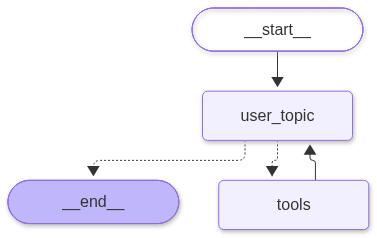

In [10]:
# Visualize the graph
from IPython.display import display, Image
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Error occurred while displaying graph: {e}")

In [11]:
# testing the flow using streaming mode
import time
from langchain_core.messages import AIMessageChunk

for chunk, metadata in graph.stream(
    {
        "topic": "Latest developments in Artificial Intelligence",
        "messages": []
    },
    config={"recursion_limit": 10},
    stream_mode="messages"
):
    # Only display output generated by the LLM node.
    if metadata.get("langgraph_node") != "user_topic":
        continue

    # Ignore tool-call chunks and empty content.
    if isinstance(chunk, AIMessageChunk) and chunk.content:
        print(chunk.content, end="", flush=True)
        time.sleep(0.02)

Let me search for more relevant AI news and research papers to ensure I have the best items for the newsletter.

Now I have enough relevant items. Let me compile the newsletter with the most relevant AI-focused items:

- **News**: The Riemann hypothesis AI story is directly about AI making a major mathematical breakthrough. The fusion power story is more about a startup backed by an AI researcher, so it's less directly about AI developments.
- **Research**: "Posterior Matching Distillation" and "RL Post-Training in Diffusion Transformers" are directly about AI/ML. "PlayCraft" is also about AI agents.

Let me pick the best 1 news article and 1 research paper that are most directly relevant to "Latest developments in AI":

- News: The Riemann hypothesis AI story is the most directly about AI capability.
- Research: "RL Post-Training in Diffusion Transformers Is Activation Steering" is a strong AI/ML paper.

Let me write the newsletter now.

---

# 🤖 AI Pulse: Your Weekly Dose of Artifici